Dataset shape: (4998, 140)
Label distribution:
 1.0    2919
0.0    2079
Name: count, dtype: int64

Normal training samples: (2335, 140)
Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - loss: 0.0047 - mae: 0.0450 - val_loss: 0.0043 - val_mae: 0.0426
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0039 - mae: 0.0404 - val_loss: 0.0034 - val_mae: 0.0387
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0029 - mae: 0.0357 - val_loss: 0.0024 - val_mae: 0.0317
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0019 - mae: 0.0277 - val_loss: 0.0016 - val_mae: 0.0259
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0013 - mae: 0.0226 - val_loss: 0.0013 - val_mae: 0.0227
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0011 - mae: 0.0208 - val_loss: 0.0012 - val_mae: 0.0219
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0010 - mae: 0.0200 - val_loss: 0.0012 - val_mae: 0.0214
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 9.

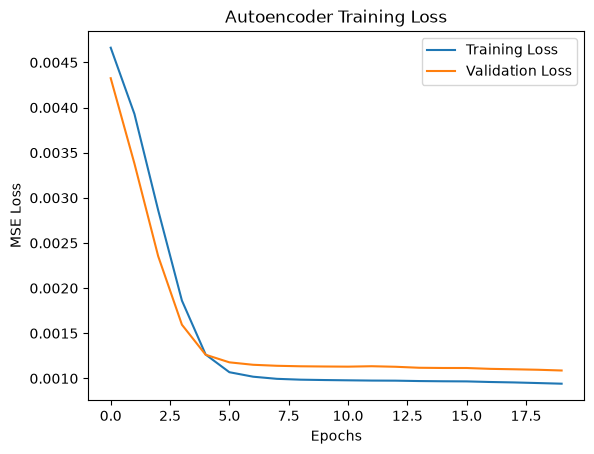


Anomaly Threshold: 0.029558938

Test Accuracy: 93.4 %

Actual vs Predicted:
Actual: Abnormal | Predicted: Abnormal | Error: 0.0461
Actual: Abnormal | Predicted: Abnormal | Error: 0.0451
Actual: Normal | Predicted: Abnormal | Error: 0.0648
Actual: Normal | Predicted: Normal | Error: 0.022
Actual: Normal | Predicted: Abnormal | Error: 0.0489
Actual: Normal | Predicted: Normal | Error: 0.0179
Actual: Abnormal | Predicted: Abnormal | Error: 0.0446
Actual: Abnormal | Predicted: Abnormal | Error: 0.047
Actual: Abnormal | Predicted: Abnormal | Error: 0.0417
Actual: Normal | Predicted: Normal | Error: 0.0177


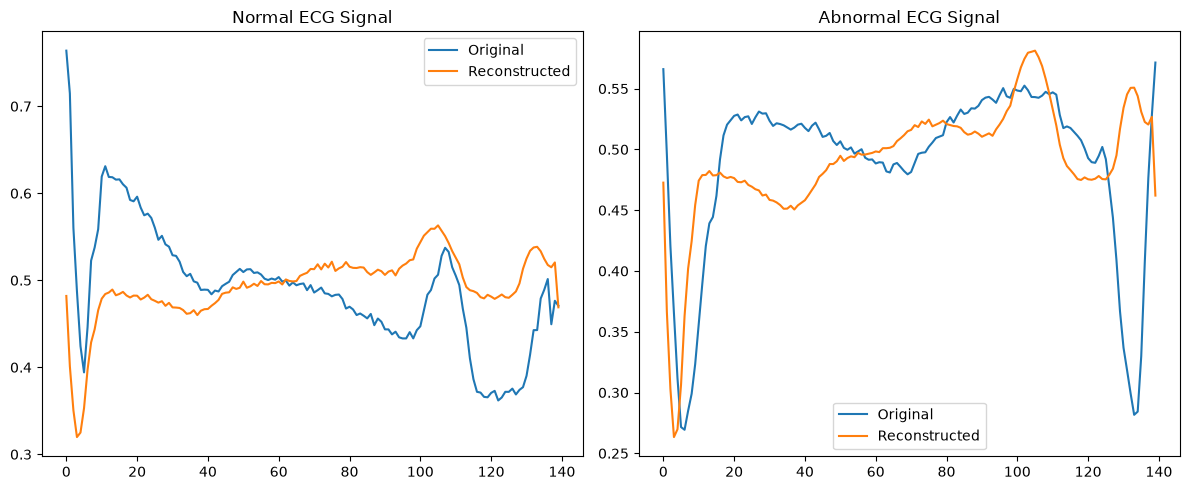

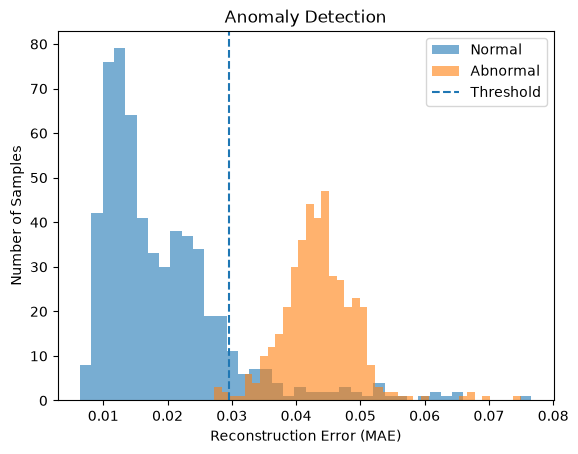

In [1]:

# a. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# 1. Load ECG dataset
df = pd.read_csv('ecg.csv', header=None).dropna()

# Last column contains labels: 1 = Normal, 0 = Abnormal
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

print("Dataset shape:", X.shape)
print("Label distribution:\n", pd.Series(y).value_counts())

# 2. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalize data between 0 and 1
min_val = X_train.min()
max_val = X_train.max()

X_train = (X_train - min_val) / (max_val - min_val)
X_test = (X_test - min_val) / (max_val - min_val)

# Convert to float32
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# Train only on normal ECG signals
normal_train = X_train[y_train == 1]

print("\nNormal training samples:", normal_train.shape)

# 3. Build Autoencoder
input_dim = X_train.shape[1]

autoencoder = tf.keras.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder - compress ECG signal
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),

    # Decoder - reconstruct ECG signal
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(input_dim, activation='sigmoid')
])

# 4. Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 5. Train using only normal ECG signals
history = autoencoder.fit(
    normal_train, normal_train,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

# Display training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.show()

# 6. Calculate reconstruction error on normal training data
train_recon = autoencoder.predict(normal_train, verbose=0)

train_error = np.mean(np.abs(normal_train - train_recon), axis=1)

# Set threshold using normal reconstruction errors
threshold = np.mean(train_error) + np.std(train_error)
print("\nAnomaly Threshold:", threshold)

# 7. Reconstruct all test ECG signals
test_recon = autoencoder.predict(X_test, verbose=0)

# Calculate reconstruction error
test_error = np.mean(np.abs(X_test - test_recon), axis=1)

# Error above threshold = Abnormal
predicted = (test_error <= threshold).astype(int)

# Calculate accuracy
accuracy = np.mean(predicted == y_test) * 100
print("\nTest Accuracy:", accuracy, "%")

# Display predictions for 10 ECG signals
print("\nActual vs Predicted:")
for i in range(10):
    actual = 'Normal' if y_test[i] == 1 else 'Abnormal'
    result = 'Normal' if predicted[i] == 1 else 'Abnormal'
    print("Actual:", actual, "| Predicted:", result,
          "| Error:", round(test_error[i], 4))

# 8. Display original and reconstructed ECG signals
normal_idx = np.where(y_test == 1)[0][0]
abnormal_idx = np.where(y_test == 0)[0][0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(X_test[normal_idx], label='Original')
plt.plot(test_recon[normal_idx], label='Reconstructed')
plt.title('Normal ECG Signal')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(X_test[abnormal_idx], label='Original')
plt.plot(test_recon[abnormal_idx], label='Reconstructed')
plt.title('Abnormal ECG Signal')
plt.legend()

plt.tight_layout()
plt.show()

# 9. Display reconstruction error distribution
plt.hist(test_error[y_test == 1], bins=40, alpha=0.6, label='Normal')
plt.hist(test_error[y_test == 0], bins=40, alpha=0.6, label='Abnormal')
plt.axvline(threshold, linestyle='--', label='Threshold')

plt.xlabel('Reconstruction Error (MAE)')
plt.ylabel('Number of Samples')
plt.title('Anomaly Detection')
plt.legend()
plt.show()
